# EJERCICIOS

In [1]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_diabetes, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    cross_val_predict,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR


In [2]:
warnings.filterwarnings("ignore", category=FutureWarning)

## EJERCICIO 1

Imagina que estás usando regresión polinomial. Trazas las curvas de aprendizaje y te das cuenta de que hay un espacio grande entre el error de entrenamiento y el error de validación. ¿Qué está pasando? Piensa en tres formas de poder arreglarlo

In [3]:
# El modelo está sobreajustando, se "ha viciado" con los datos de entrenamiento y no es capaz de generalizar, algunas formas de corregirlo 
# pueden ser bajar el grado del polinomio, de esa manera tendrá menos libertad para ajustar a cada punto y estará obligado a generalizar más,
# aplicar regularizacion mediante ridge, lasso o elastic net (combinacion de ambas), con esta regularizacion castigamos al modelo por hacer 
# curvas bruscas que es precisamente lo que hace un polinomio de grado alto para tratar de ajustarse a todos los datos, tambien se podría 
# aumentar el tamaño del dataset, aunque sería lo menos optimo

## EJERCICIO 2

Imagina que estás utilizando regresión de Ridge y observas que el error de entrenamiento y el error de validación son casi iguales y bastante altos. ¿Deberías incrementar el hiperparámetro de regularización o reducirlo (α)?

In [4]:
# Habría que bajarlo, ambos errores son altos, lo que quiere decir que está subajustando, con una regularización alta 
# hacemos que el modelo sea más rígido, es decir, que no le estamos dejando libertad para ajustarse a los datos

## EJERCICIO 3

Ejercicio de Regresión con el Conjunto de Datos de Diabetes

* Objetivo: El objetivo de este ejercicio es desarrollar un modelo de regresión que pueda predecir la progresión de la diabetes un año después del inicio basándose en diversas mediciones clínicas.

* Datos: Utilizarás el conjunto de datos de diabetes proporcionado por Scikit-Learn, que contiene diez variables base (edad, sexo, índice de masa corporal, presión arterial y seis mediciones de suero sanguíneo) para 442 pacientes.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [5]:
dataset = load_diabetes(as_frame=True)
X, y = dataset.data, dataset.target

#### EXPLORAR LOS DATOS

Muestra los primero datos de X e y

In [6]:
print(y.head())
X.head()

0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


Usa .describe y .info para ver un poco de información

In [7]:
print(X.info())
X.describe()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB
None


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


Representa cada una de la características

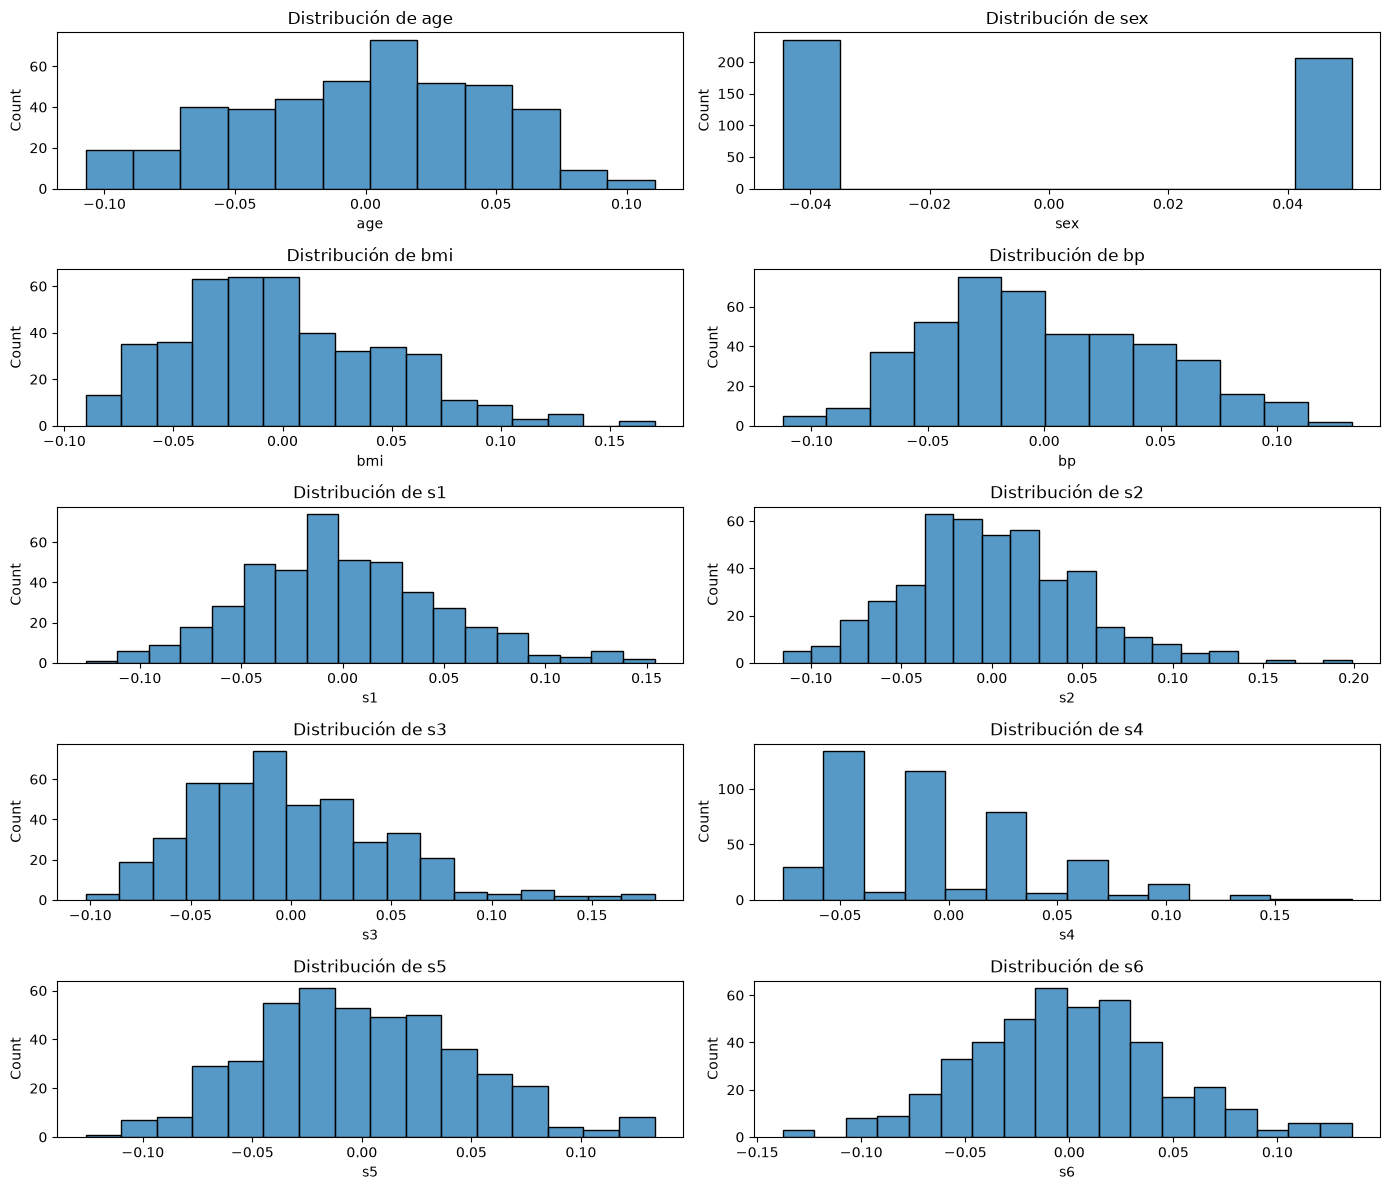

In [8]:
fig, axes = plt.subplots(5, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(X.columns):
    sns.histplot(data=X, x=col, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")

plt.tight_layout()
plt.show()

Muestra la matriz de correlaciones

In [9]:
matriz_correlacion = X.corr()

matriz_correlacion.style.background_gradient()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000


#### DIVIDIR LOS DATOS

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.85, random_state=42)

#### PREPARAR LOS DATOS

Como puedes ver en los gráficos los datos ya están preparados

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Crea y entrena el modelo con diferentes algoritmos y muestra los resultados obtenidos con validación cruzada y utilizando la métrica RMSE para medir el error

In [11]:
modelos = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "SVR": SVR(),
}

scores = {}
for nombre, modelo in modelos.items():
    resultado = cross_val_score(modelo, X_train, y_train, scoring="neg_root_mean_squared_error") * -1
    scores[nombre] = {
        "media": resultado.mean(),
        "desviacion": resultado.std(),
        "porcentaje": round(resultado.std() / resultado.mean() * 100, 4)
    }

pd.DataFrame(scores).T

,media,desviacion,porcentaje
LinearRegression,54.718155,4.327376,7.9085
Ridge,59.291333,3.878904,6.5421
Lasso,62.616863,4.789189,7.6484
SVR,71.943123,6.591457,9.1620


Calcula el máximo de y (del dataset original) y el mínimo de y (del dataset original) para ver con prespectiva si RMSE es aceptable o no.

In [12]:
print(f"y maxima: {y.max()}")
print(f"y minima: {y.min()}")
scores = {}
for nombre, modelo in modelos.items():
    resultado = cross_val_score(modelo, X_train, y_train, scoring="neg_root_mean_squared_error") * -1
    scores[nombre] = {
        "media": resultado.mean(),
        "desviacion": resultado.std(),
        "porcentaje": (resultado.mean() / (y.max() - y.min())) * 100
    }

pd.DataFrame(scores).T

y maxima: 346.0
y minima: 25.0


,media,desviacion,porcentaje
LinearRegression,54.718155,4.327376,17.046154
Ridge,59.291333,3.878904,18.470820
Lasso,62.616863,4.789189,19.506811
SVR,71.943123,6.591457,22.412188


### OPTIMIZACIÓN DEL MODELO

Vamos a suponer que el mejor modelo que has obtenido es con Ridge y vamoas a aplicar búsqueda exhaustiva para el parámetro alpha.

In [13]:
parametros = {
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(modelos["Ridge"], parametros, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.0001, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting

Evalúa este mejor modelo en el conjunto de pruebas

In [14]:
resultado = grid_search.best_estimator_.predict(X_test)
rmse_ridge = root_mean_squared_error(y_test, resultado)

print(rmse_ridge)
(rmse_ridge / (y.max() - y.min())) * 100

56.48698951637322


np.float64(17.5971929957549)

### PRESENTACIÓN DEL MODELO

Guarda el modelo en un archivo

In [15]:
joblib.dump(grid_search.best_estimator_, "../Resultados/modelo_final_diabetes.joblib")

['../Resultados/modelo_final_diabetes.joblib']

Opcional: hacer un script de Python que pida los datos y te prediga el resultado

## EJERCICIO 4

Usa regresión logística para crear un modelo que deduzca el tipo de flor iris

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [16]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

len(X_iris)

150

#### EXPLORAR LOS DATOS

Visualiza los datos

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


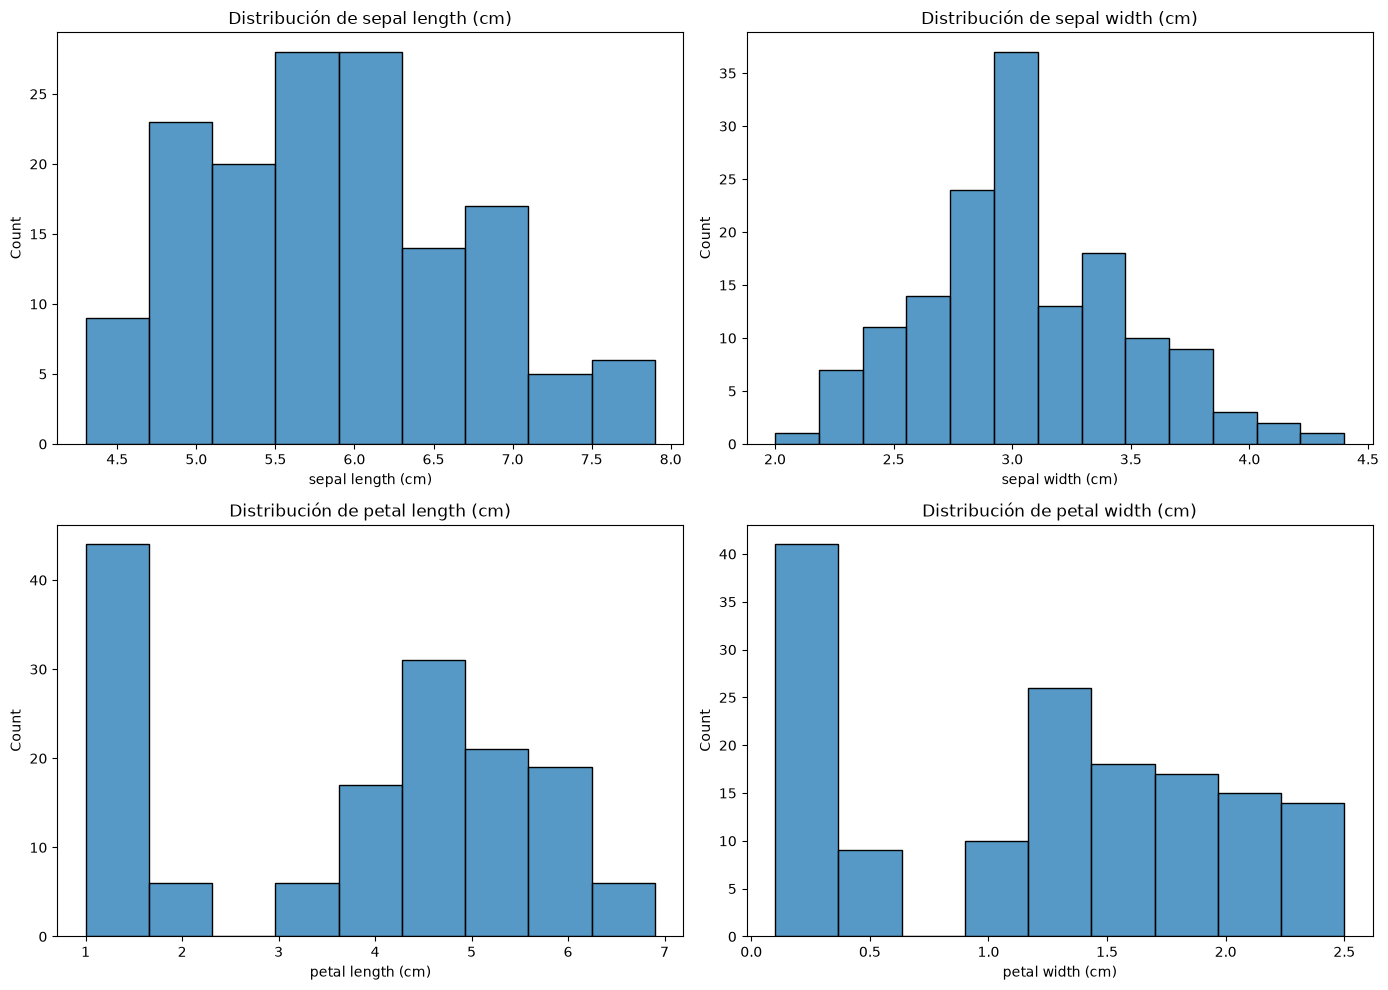

In [17]:
display(X_iris.head())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(X_iris.columns):
    sns.histplot(data=X_iris, x=col, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")

plt.tight_layout()
plt.show()

Representa la matriz de correlaciones

In [18]:
matrix_correlacion = X_iris.corr()
matrix_correlacion.style.background_gradient()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


#### DIVIDIR LOS DATOS

In [19]:
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(X_iris, y_iris, train_size=0.85, random_state=42)

#### PREPARAR LOS DATOS

Solo hay que estandarizar las columnas y por lo tanto se puede hacer directamente en la pipeline que define el modelo en el siguiente punto

### SELECCIÓN Y ENTRENAMIENTO DEL MODELO

Crear y entrenar el modelo con regresión logística y validacion cruzada ¿cuál es la exactitud en el conjunto de entrenamiento?

In [20]:
pipeline_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

predicciones = cross_val_predict(pipeline_lr, X_iris_train, y_iris_train)
exactitud = accuracy_score(y_iris_train, predicciones)

print(exactitud)

0.9606299212598425


Calcula matriz de confusion, precision, recall y f1 en el conjunto de entrenamiento

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

precision = precision_score(y_iris_train, predicciones, average="macro")
sensibilidad = recall_score(y_iris_train, predicciones, average="macro")
f1 = f1_score(y_iris_train, predicciones, average="macro")

print(f"Exactitud: {exactitud}")
print(f"Precisión: {precision}")
print(f"Sensibilidad: {sensibilidad}")
print(f"F1: {f1}")

# ConfusionMatrixDisplay.from_predictions(
#     y_iris_train, predicciones, normalize="true", values_format=".0%"
# )
# plt.show()

Exactitud: 0.9606299212598425
Precisión: 0.9611111111111111
Sensibilidad: 0.9604582409460458
F1: 0.9606972765524575


¿Qué podemos deducir?

In [22]:
# La clase 0 se distingue a la perfeccion con estos datos, en cambio las clases 1 y 2 se confunden entre sí algunas veces

### OPTIMIZACIÓN DEL MODELO

Aplica búsqueda exhaustiva con los hiperparámetros de LogisticRegression (C y solver) y guarda el mejor modelo en una variable.

In [23]:
parametros = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
}

optimizador = GridSearchCV(
    pipeline_lr,
    param_grid=parametros,
    scoring="accuracy",
    cv=3,
    n_jobs=-1
)
optimizador.fit(X_iris_train, y_iris_train)

modelo_optimizado = optimizador.best_estimator_

/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/

### EVALUACIÓN DEL MODELO

Evalua este mejor modelo en el conjunto de pruebas (exactitud, matriz de confusión, precision, recall y f1)

Exactitud: 1.0
Precisión: 1.0
Sensibilidad: 1.0
F1: 1.0


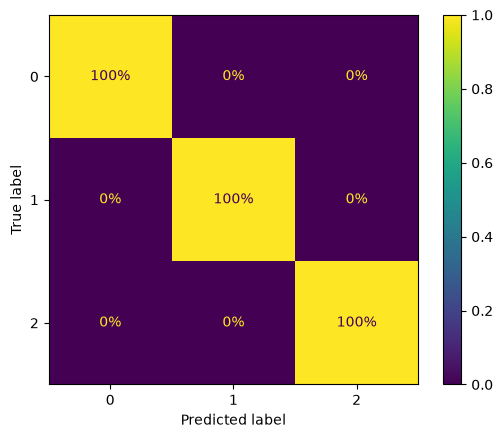

In [24]:
predicciones = modelo_optimizado.predict(X_iris_test)

exactitud = accuracy_score(y_iris_test, predicciones)
precision = precision_score(y_iris_test, predicciones, average="macro")
sensibilidad = recall_score(y_iris_test, predicciones, average="macro")
f1 = f1_score(y_iris_test, predicciones, average="macro")

print(f"Exactitud: {exactitud}")
print(f"Precisión: {precision}")
print(f"Sensibilidad: {sensibilidad}")
print(f"F1: {f1}")

ConfusionMatrixDisplay.from_predictions(
    y_iris_test, predicciones, normalize="true", values_format=".0%"
)
plt.show()

### PRESENTACIÓN DEL MODELO

Guarda el modelo en un archivo

In [25]:
joblib.dump(modelo_optimizado, "../Resultados/modelo_final_iris.joblib")

['../Resultados/modelo_final_iris.joblib']

## EJERCICIO 5

Vamos a trabajar con los siguientes datos generado.

In [26]:
np.random.seed(42)
m = 1000
X_train = 4 * np.random.rand(m, 1) 
y_train = 0.5 * X_train ** 5 -2* X_train ** 2 + 0.50 * X_train + 2 + np.random.randn(m, 1)

m=100
X_test = 4 * np.random.rand(m, 1) 
y_test = 0.5 * X_test ** 5 -2* X_test ** 2 + 0.50 * X_test + 2 + np.random.randn(m, 1)


Representa los datos (entrenamiento y pruebas en la misma gráfica)

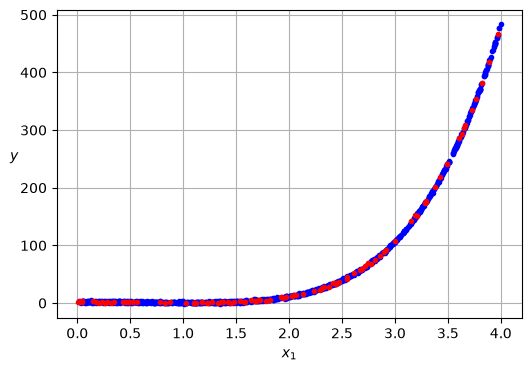

In [27]:
plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "b.")
plt.plot(X_test, y_test, "r.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.grid()
plt.show()

Crea un modelo de regresión utilizando PolynomialFeatures, para ver cuál es el mejor degree representa gráficamente el error de entrenamiento y el error de prueba para diferentes degree.
Justifica que degree escoges y crea una pipeline para poder aplicar tu modelo.

Grado: 1, error entrenamiento:70.58707757228053 , error test: 67.9594102796689
Grado: 2, error entrenamiento:26.6743028106467 , error test: 26.668566489091113
Grado: 3, error entrenamiento:6.09957382574732 , error test: 5.947271233059012
Grado: 4, error entrenamiento:1.165424617104871 , error test: 1.211977053366644
Grado: 5, error entrenamiento:0.9844595293237262 , error test: 1.0713947209793002
Grado: 6, error entrenamiento:0.9841937135489751 , error test: 1.0734259425083568
Grado: 7, error entrenamiento:0.9840616905754953 , error test: 1.071940305184142
Grado: 8, error entrenamiento:0.9835305231371149 , error test: 1.0688582801511974


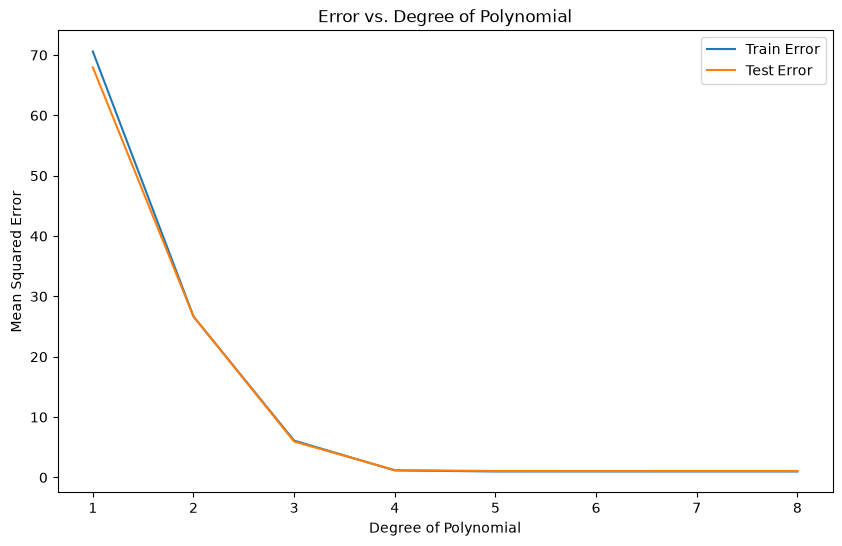

In [28]:
degrees = range(1, 9)
train_errors = []
test_errors = []

for degree in degrees:
    model=make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_error=root_mean_squared_error(y_train, y_train_pred)
    test_error=root_mean_squared_error(y_test, y_test_pred)
    train_errors.append(train_error)
    test_errors.append(test_error)
    print(f"Grado: {degree}, error entrenamiento:{train_error} , error test: {test_error}")
plt.figure(figsize=(10, 6))
plt.plot(degrees, train_errors, label='Train Error')
plt.plot(degrees, test_errors, label='Test Error')
plt.xlabel('Degree of Polynomial')
plt.ylabel('Mean Squared Error')
plt.title('Error vs. Degree of Polynomial')
plt.legend()
plt.show()

# A la vista de los errores representados, a partir del grado 5 todos los modelos se comportan
# de forma similar, con lo que elegiré el modelo de menor grado dentro de estos, el de grado 5
modelo_polinomico = make_pipeline(
    PolynomialFeatures(degree=5, include_bias=False),
    StandardScaler(),
    LinearRegression(),
)

Entrena el modelo y calcula el error en el conjunto de pruebas

In [29]:
modelo_polinomico.fit(X_train, y_train)
root_mean_squared_error(y_test, modelo_polinomico.predict(X_test))

1.0713947209793002

Aplica al modelo algún tipo de regularización que mejore el modelo

In [30]:
alphas = {}

for regularizador_str in ["Ridge", "Lasso"]:
    for alpha_value_int in range(0, 11):
        alpha_value = alpha_value_int / 10

        regularizador = Ridge(alpha_value) if regularizador_str == "Ridge" else Lasso(alpha_value)

        modelo_regularizado = make_pipeline(
            PolynomialFeatures(degree=5, include_bias=False),
            StandardScaler(),
            regularizador
        )
        modelo_regularizado.fit(X_train, y_train)

        rmse = root_mean_squared_error(y_test, modelo_regularizado.predict(X_test))
        if regularizador_str not in alphas:
            alphas[regularizador_str] = {}
        alphas[regularizador_str][str(alpha_value)] = rmse

display(pd.DataFrame(alphas).sort_values(["Ridge","Lasso"]).T)

# Viendo los nuevos errores, el único modelo con regularización que parece mejorar algo es usando regresión de Ridge con el alpha a 0.1
modelo_regularizado = make_pipeline(
    PolynomialFeatures(degree=5, include_bias=False),
    StandardScaler(),
    Ridge(0.1)
)

/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.537638e+03, tolerance: 1.426e+03
  model = cd_fast.enet_coordinate_descent(


,0.1,0.0,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
Ridge,1.056637,1.071395,1.074059,1.093446,1.113872,1.136033,1.160365,1.187001,1.215880,1.246832,1.279635
Lasso,1.189191,1.531777,1.431007,1.577137,1.775988,2.011602,2.270614,2.550215,2.841828,3.140996,3.381824


Dibuja las curvas de aprendizaje para este último modelo e interpretalas

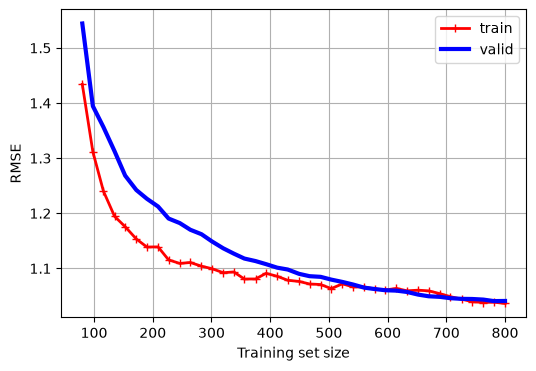

In [31]:
train_sizes, train_scores, valid_scores = learning_curve(
    modelo_regularizado, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 40), cv=5,
    scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.legend(loc="upper right")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
plt.show()

# La diferencia entre el error de entrenamiento y el de validación es 
# pequeña, además la curva que trazan ambos es similar, ambas disminuyen
# gradualmente a medida que aumenta la cantidad de datos, convergiendo 
# relativamente pronto, debido a esto se puede deducir que el modelo 
# generaliza bastante bien, es decir, que no sufre de sobreajuste, además
# el error final es bajo (alrededor de 1.05), lo que quiere decir que 
# tampoco sufre de infraajuste, por último, ambas curvas están bastante 
# planas al final, por lo que añadir más datos de entrenamiento 
# no mejoraría el resultado de forma significativa

## EJERCICIO 6

Intenta predecir las emisiones de CO2 con el menor error posible (sigue todos los pasos incluido crear un script para que haga predicciones).

Prueba diferentes modelos para intentar construir el mejor modelo posible (explica todos los pasos que das hasta llegar a la solución, quiero ver también los modelos que pruebas y luego los rechazas)

Dataset: https://www.kaggle.com/datasets/midhundasl/co2-emission-of-cars-dataset

In [ ]:
# Primero cargamos los datos y los exploramos, borramos columnas innecesarias

vehicle_dataset = pd.read_csv('../datos/co2.csv')
print(vehicle_dataset.info())
display(vehicle_dataset.describe().T)
vehicle_dataset = vehicle_dataset.drop("Unnamed: 5", axis=1)
vehicle_dataset

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Car         36 non-null     str    
 1   Model       36 non-null     str    
 2   Volume      36 non-null     int64  
 3   Weight      36 non-null     int64  
 4   CO2         36 non-null     int64  
 5   Unnamed: 5  0 non-null      float64
dtypes: float64(1), int64(3), str(2)
memory usage: 1.8 KB
None


,count,mean,std,min,25%,50%,75%,max
Volume,36.0,1611.111111,388.975047,900.0,1475.00,1600.0,2000.00,2500.0
Weight,36.0,1292.277778,242.123889,790.0,1117.25,1329.0,1418.25,1746.0
CO2,36.0,102.027778,7.454571,90.0,97.75,99.0,105.00,120.0
Unnamed: 5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Car,Model,Volume,Weight,CO2
0,Toyota,Aygo,1000,790,99
1,Mitsubishi,Space Star,1200,1160,95
2,Skoda,Citigo,1000,929,95
3,Fiat,500,900,865,90
4,Mini,Cooper,1500,1140,105
5,VW,Up!,1000,929,105
6,Skoda,Fabia,1400,1109,90
7,Mercedes,A-Class,1500,1365,92
8,Ford,Fiesta,1500,1112,98
9,Audi,A1,1600,1150,99
